In [57]:
import numpy as np
import math 
import matplotlib.pyplot as plt
import pandas as pd
import scipy.optimize as scpo


class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"):
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","x","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()


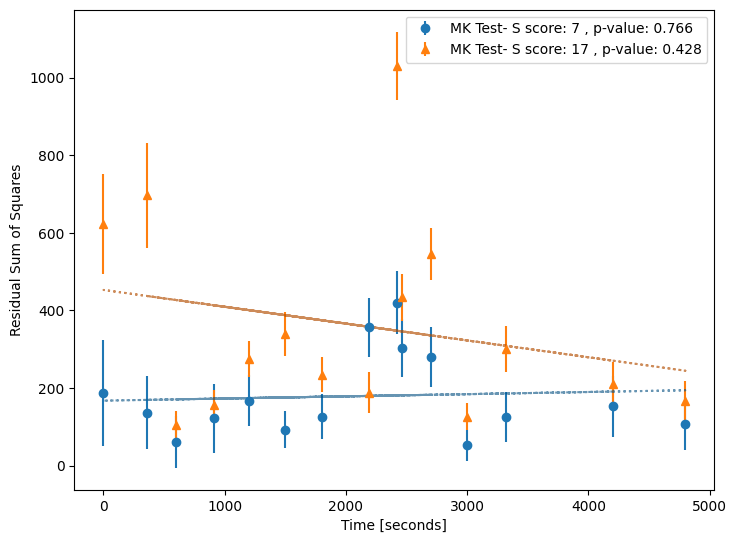

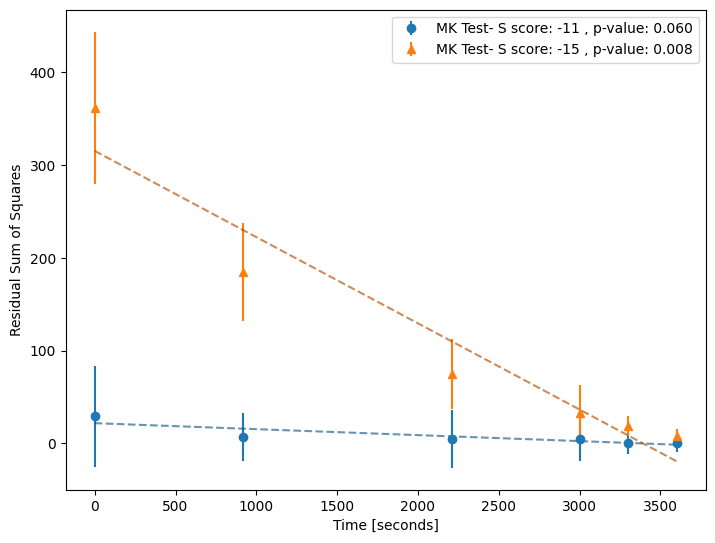

In [112]:
import statistics
import pymannkendall as mk


###########################Inputs################
file_name = "Bridge_project"
sheets = ["Penta1","BP1","MP1","SP1","Penta2","BP2","MP2","SP2"]
times = [[1200,1800,1500,4800,3000,2460,600,2190,2420,0,2700,910,4200,355,3320],[0,3900,600,1200,2700,6500,3301,2100,5400,4500],[0,600,1200,1800,2580,3000,3600],[0,2148,1200,610,2480,3000,1523],[0,301,1200,2105,4502,3900,2715,5100],[0,1202,2700,3900,5400,6300,601,1800,3300,4500],
         [0,5100,900,3010,4500,2100,3606,1500],[0,920,2212,3000,3300,3600]]
#################
Rs = []
Rs_error = []

for s in range(len(sheets)):
    all_data = []
    full_xl = pd.read_excel(file_name + ".xlsx",sheet_name=sheets[s])

    for i in range(len(full_xl.iloc[0].values.tolist())):
        if i%2 == 0:
            x = full_xl.iloc[:,i].values.tolist()
            end_index = 0
            stop_lp = True
            while stop_lp:
                if math.isnan(x[end_index]):
                    stop_lp = False
                elif end_index==len(x)-1:
                    stop_lp = False
                else:
                    end_index +=1
            x = x[:end_index]
        else:
            y = full_xl.iloc[:,i].values.tolist()
            end_index = 0
            stop_lp = True
            while stop_lp:
                if math.isnan(y[end_index]):
                    stop_lp = False
                elif end_index==len(y)-1:
                    stop_lp = False
                else:
                    end_index +=1
            y = y[:end_index]
            all_data += [([x,y])]



    #### Data Analysis####
    dt = []

    def poly(x,a,b,c,d,e):
        return a*(x**4)+b*(x**3)+c*(x**2)+d*(x)+e
    def lin(x,a,b):
        return a*np.sqrt((x)**2)+b
    def rss_p(x,y,a,b,c,d,e):
            summ = 0
            for i in range(len(x)):
                summ += (y[i]-(a*(x[i]**4)+b*(x[i]**3)+c*(x[i]**2)+d*(x[i])+e))**2
            return summ 
    def rss_l(x,y,a,b):
            summ = 0
            for i in range(len(x)):
                summ += (y[i]-(a*np.sqrt((x[i])**2)+b))**2
            return summ 
    def w_l(x,y,a,b):
        return (y-(a*np.sqrt((x)**2)+b))**2
    
    def w_p(x,y,a,b,c,d,e):
        return (y-(a*(x**4)+b*(x**3)+c*(x**2)+d*(x)+e))**2



    square_resid_p = []
    square_resid_l = []
    square_resid_p_err = []
    square_resid_l_err = []


    for i in range(len(all_data)):
        ##shifitng##
        cur_data = all_data[i]
        curz_data = [[],[]]
        zx = ((cur_data[0][-1] - cur_data[0][0])/2) + cur_data[0][0]
        zy = cur_data[1][0]
        for j in range(len(cur_data[0])):
            curz_data[0] += [(cur_data[0][j]- zx)]
            curz_data[1] += [cur_data[1][j] - zy]
        curz_data = np.array(curz_data)

        ##fitting the curve##
        cof_fit_p , covar_p = scpo.curve_fit(poly,curz_data[0],curz_data[1])
        cof_fit_l , covar_l = scpo.curve_fit(lin,curz_data[0],curz_data[1])

        square_resid_p += [rss_p(curz_data[0],curz_data[1],cof_fit_p[0],cof_fit_p[1],cof_fit_p[2],cof_fit_p[3],cof_fit_p[4])]
        square_resid_l += [rss_l(curz_data[0],curz_data[1],cof_fit_l[0],cof_fit_l[1])]

        w_val_err_l = []
        w_val_err_p = []

        
        for k in range(len(curz_data[0])):
            w_dt_l = UDS([[curz_data[0][k], 3*0.16],[curz_data[1][k],3*0.16],[cof_fit_l[0],np.sqrt(covar_l[0,0])],[cof_fit_l[1],np.sqrt(covar_l[1,1])]])
            w_val_err_l += [w_dt_l.functional_err(w_l)]
            w_dt_p = UDS([[curz_data[0][k], 3*0.16],[curz_data[1][k],3*0.16],[cof_fit_p[0],np.sqrt(covar_p[0,0])],[cof_fit_p[1],np.sqrt(covar_p[1,1])],[cof_fit_p[2],np.sqrt(covar_p[2,2])],[cof_fit_p[3],np.sqrt(covar_p[3,3])],[cof_fit_p[4],np.sqrt(covar_p[4,4])]])
            w_val_err_p += [w_dt_p.functional_err(w_p)]
        R_l_val = sum(np.array(w_val_err_l)[:,0])
        R_l_err = sum((np.array(w_val_err_l)[:,1])**2)
        R_l_err = np.sqrt(R_l_err)
        R_p_val = sum(np.array(w_val_err_p)[:,0])
        R_p_err = sum((np.array(w_val_err_p)[:,1])**2)
        R_p_err = np.sqrt(R_p_err)
        
        square_resid_p_err += [[R_p_val,R_p_err]]
        square_resid_l_err += [[R_l_val,R_l_err]]

        

    Rs += [[square_resid_p,square_resid_l]]
    Rs_error += [[np.array(square_resid_p_err),np.array(square_resid_l_err)]]

# for m in range(len(sheets)):
#     print("")
#     print(sheets[m])
#     print("Poly:")
#     print(mk.original_test(Rs_error[m][0][:,0]))
#     print("Linear")
#     print(mk.original_test(Rs_error[m][1][:,0]))

#Plotting#
def Line(x, gradient, intercept): 
    return gradient*x + intercept

pb_coef_p, pb_cov_err_p = scpo.curve_fit(Line,times[0],Rs_error[0][0][:,0])
pb_coef_l, pb_cov_err_l = scpo.curve_fit(Line,times[0],Rs_error[0][1][:,0])

pb_bfl_p = Line(np.array(times[0]),pb_coef_p[0],pb_coef_p[1])
pb_bfl_l = Line(np.array(times[0]),pb_coef_l[0],pb_coef_l[1])


fig1 = plt.figure(1)
ax1 = fig1.add_axes((0,0,1,1))
#ax1.set_title("Pentagonal on Top")
ax1.errorbar(times[0],Rs_error[0][0][:,0],yerr=Rs_error[0][0][:,1],fmt="o",label = "MK Test- S score: 7 , p-value: 0.766")
ax1.errorbar(times[0],Rs_error[0][1][:,0],yerr=Rs_error[0][1][:,1],fmt="^",label = "MK Test- S score: 17 , p-value: 0.428")
ax1.plot(times[0],pb_bfl_p,color = (0,0.3,0.5,0.6),ls=':')
ax1.plot(times[0],pb_bfl_l,color = (0.7,0.3,0,0.65),ls=':')
ax1.set_ylabel("Residual Sum of Squares")
ax1.set_xlabel("Time [seconds]")

plt.legend()
fig1.savefig("Pentagonal on Top.png",bbox_inches='tight')
plt.show()


# fig2 = plt.figure(2)
# ax2 = fig2.add_axes((0,0,1,1))
# ax2.set_title("Big Paraboloid on Top")
# ax2.errorbar(times[1],Rs_error[1][0][:,0],yerr=Rs_error[1][0][:,1],fmt="o",label = "polynomial")
# ax2.errorbar(times[1],Rs_error[1][1][:,0],yerr=Rs_error[1][1][:,1],fmt="o",label = "linear")
# ax2.set_ylabel("Resid Square")
# ax2.set_xlabel("time")

# plt.legend()
# #fig2.savefig("Big Paraboloid on Top.png",bbox_inches='tight')
# plt.show()

# fig3 = plt.figure(3)
# ax3 = fig3.add_axes((0,0,1,1))
# ax3.set_title("Medium Paraboloid on Top")
# ax3.errorbar(times[2],Rs_error[2][0][:,0],yerr=Rs_error[2][0][:,1],fmt="o",label = "polynomial")
# ax3.errorbar(times[2],Rs_error[2][1][:,0],yerr=Rs_error[2][1][:,1],fmt="o",label = "linear")
# ax3.set_ylabel("Resid Square")
# ax3.set_xlabel("time")

# plt.legend()
# #fig3.savefig("Medium Paraboloid on Top.png",bbox_inches='tight')
# plt.show()


# fig4 = plt.figure(4)
# ax4 = fig4.add_axes((0,0,1,1))
# ax4.set_title("Small Paraboloid on Top")
# ax4.errorbar(times[3],Rs_error[3][0][:,0],yerr=Rs_error[3][0][:,1],fmt="o",label = "polynomial")
# ax4.errorbar(times[3],Rs_error[3][1][:,0],yerr=Rs_error[3][1][:,1],fmt="o",label = "linear")
# ax4.set_ylabel("Resid Square")
# ax4.set_xlabel("time")

# plt.legend()
# #fig4.savefig("Small Paraboloid on Top.png",bbox_inches='tight')
# plt.show()

# fig5 = plt.figure(5)
# ax5 = fig5.add_axes((0,0,1,1))
# ax5.set_title("Pentagonal on Bottom")
# ax5.errorbar(times[4],Rs_error[4][0][:,0],yerr=Rs_error[4][0][:,1],fmt="o",label = "polynomial")
# ax5.errorbar(times[4],Rs_error[4][1][:,0],yerr=Rs_error[4][1][:,1],fmt="o",label = "linear")
# ax5.set_ylabel("Resid Square")
# ax5.set_xlabel("time")

# plt.legend()
# #fig5.savefig("Pentagonal on Bottom.png",bbox_inches='tight')
# plt.show()

# fig6 = plt.figure(6)
# ax6 = fig6.add_axes((0,0,1,1))
# ax6.set_title("Big Paraboloid on Bottom")
# ax6.errorbar(times[5],Rs_error[5][0][:,0],yerr=Rs_error[5][0][:,1],fmt="o",label = "polynomial")
# ax6.errorbar(times[5],Rs_error[5][1][:,0],yerr=Rs_error[5][1][:,1],fmt="^",label = "linear")
# ax6.set_ylabel("Resid Square")
# ax6.set_xlabel("time")

# plt.legend()
# #fig6.savefig("Big Paraboloid on Bottom.png",bbox_inches='tight')
# plt.show()

# fig7 = plt.figure(7)
# ax7 = fig7.add_axes((0,0,1,1))
# ax7.set_title("Medium Paraboloid on Bottom")
# ax7.errorbar(times[6],Rs_error[6][0][:,0],yerr=Rs_error[6][0][:,1],fmt="o",label = "polynomial")
# ax7.errorbar(times[6],Rs_error[6][1][:,0],yerr=Rs_error[6][1][:,1],fmt="^",label = "linear")
# ax7.set_ylabel("Resid Square")
# ax7.set_xlabel("time")

# plt.legend()
# #fig7.savefig("Medium Paraboloid on Bottom.png",bbox_inches='tight')
# plt.show()




spb_coef_p, spb_cov_err_p = scpo.curve_fit(Line,times[7],Rs_error[7][0][:,0])
spb_coef_l, spb_cov_err_l = scpo.curve_fit(Line,times[7],Rs_error[7][1][:,0])

spb_bfl_p = Line(np.array(times[7]),spb_coef_p[0],spb_coef_p[1])
spb_bfl_l = Line(np.array(times[7]),spb_coef_l[0],spb_coef_l[1])


fig8 = plt.figure(8)
ax8 = fig8.add_axes((0,0,1,1))
#ax8.set_title("Small Paraboloid on Bottom")
ax8.errorbar(times[7],Rs_error[7][0][:,0],yerr=Rs_error[7][0][:,1],fmt="o",label = "MK Test- S score: -11 , p-value: 0.060")
ax8.errorbar(times[7],Rs_error[7][1][:,0],yerr=Rs_error[7][1][:,1],fmt="^",label = "MK Test- S score: -15 , p-value: 0.008")
ax8.plot(times[7],spb_bfl_p,color = (0,0.3,0.5,0.6),ls='--')
ax8.plot(times[7],spb_bfl_l,color = (0.7,0.3,0,0.65),ls='--')
ax8.set_ylabel("Residual Sum of Squares")
ax8.set_xlabel("Time [seconds]")

plt.legend()
#fig8.savefig("Small Paraboloid on Bottom.png",bbox_inches='tight')
plt.show()

